<a href="https://colab.research.google.com/github/Avrlst/Plat-nomer-tracking/blob/main/PlatnomerTracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics easyocr opencv-python-headless matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 86.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 27.8 MB/s eta 0:00:00


Sedang memuat Model AI.... (Proses ini mengunduh otak Digital nya terlebih dahulu )

0: 448x640 4 cars, 10.8ms
Speed: 2.4ms preprocess, 10.8ms inference, 2.4ms postprocess per image at shape (1, 3, 448, 640)

--- Memulai Analisis gambar ---
Teks terdeteksi B1Z94 SAB | tingkat keyakinan AI: 61.04%


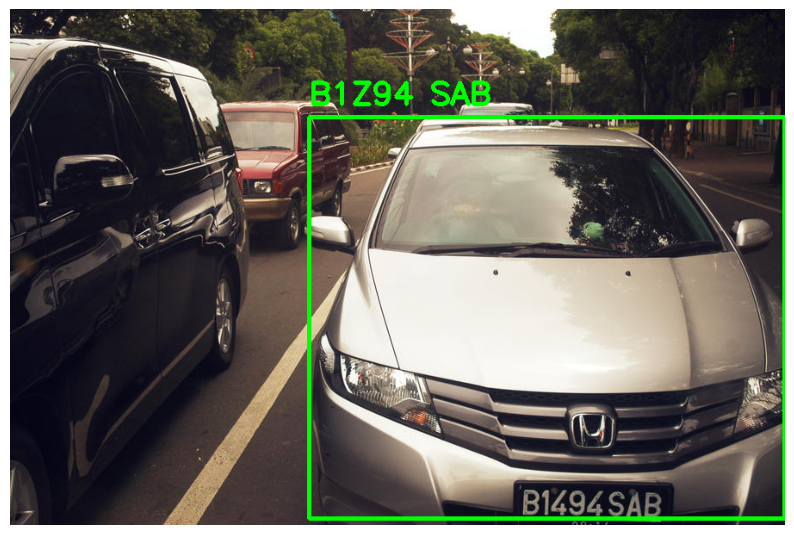

In [ ]:
import cv2
import easyocr
import matplotlib.pyplot as plt
from ultralytics import YOLO

# init model,memanggil YOLO v8 dan easyocr

print("Sedang memuat Model AI.... (Proses ini mengunduh otak Digital nya terlebih dahulu )")
model = YOLO('yolov8n.pt')
reader = easyocr.Reader(['en'])

#Baca Gambar menggunakan opencv
path_gambar = 'mobil1.jpg'
img = cv2.imread(path_gambar)

#Deteksi Mobil menggunakan YOLO,mencari semua objek dalam foto
result = model(img)[0]

print("\n--- Memulai Analisis gambar ---")

#Looping:memeriksa setiap objek yang ditemukan YOLO
for box in result.boxes:
  x1,y1,x2,y2 = map(int, box.xyxy[0]) # Mengambil koordinat kotak pembatas objek (x1, y1 = pojok kiri atas, x2, y2 = pojok kanan bawah)

  cls = int(box.cls[0]) # Keterangan kelas objek (misal: 2 untuk mobil, 3 untuk motor, 7 untuk truk)

  if cls in[2,3,5,7]:
    #pcd
    kendaraan_crop =img[y1:y2, x1:x2]

    # PCD: Ubah potongan gambar kendaraan menjadi Abu-abu (Grayscale)
    # Tujuannya agar EasyOCR lebih fokus pada bentuk huruf, bukan warna bodi mobil

    gray_kendaraan = cv2.cvtColor(kendaraan_crop,cv2.COLOR_BGR2GRAY)

    hasil_ocr = reader.readtext(gray_kendaraan) # 4. PROSES OCR: EasyOCR membaca teks di dalam area kendaraan tersebut

    # Memeriksa hasil pembacaan teks di dalam area mobil
    for(bbox,text,prob) in hasil_ocr:
      # Jika akurasi pembacaan teks di atas 40% dan teksnya tidak terlalu pendek
      if prob > 0.4 and len(text) > 3:
        print(f"Teks terdeteksi {text.upper()} | tingkat keyakinan AI: {prob*100:.2f}%")\

        # Menggambar kotak hijau pada plat nomor di gambar asli menggunakan OpenCV
        cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0),4)

        # Menuliskan teks hasil pembacaan di atas kotak tersebut
        cv2.putText(img, text.upper(), (x1, y1 - 15), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)

# 5. TAMPILKAN HASIL AKHIR
# OpenCV membaca warna dalam format BGR, sedangkan Matplotlib menampilkan dalam RGB. Kita balik dulu warnanya.
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off') # Menghilangkan angka koordinat grafik
plt.show()


In [ ]:
!pip install ultralytics easyocr opencv-python-headless matplotlib